# 01 - Layer 1 Multi-Stage Filtering Pipeline

This notebook covers case-study section **3.1 Layer 1: Multi-Stage Filtering Pipeline**.

It is intentionally not a broad exploratory notebook. It runs and inspects the actual project pipeline:

1. **Stage A: Hard Filters** - automatic reject rules from configurable policy thresholds.
2. **Stage B: Sector-Agnostic Benchmark Scoring** - expanded decision-time benchmark features plus peer outlier detection.
3. **Stage C: XGBoost Credit Model** - probability model with time-aware GridSearchCV and out-of-time validation.

The code below calls the repository scripts and then loads their generated CSVs so the outputs are visible as dataframes.

## 1. Setup

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

In [2]:
# Resolve project root whether running from repo root or notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'scripts').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORTS_DIR = PROJECT_ROOT / 'reports'
MODELS_DIR = PROJECT_ROOT / 'models'
DATE_COLS = ['invoice_date', 'expected_payment_date', 'actual_resolution_date']

DATA_CANDIDATES = sorted((PROJECT_ROOT / 'utils').glob('*synthetic*.csv*'))
if not DATA_CANDIDATES:
    DATA_CANDIDATES = sorted((PROJECT_ROOT / 'utils').glob('*.csv*'))
if len(DATA_CANDIDATES) != 1:
    raise FileNotFoundError(f'Expected one dataset CSV under utils/, found: {DATA_CANDIDATES}')
DATA_PATH = DATA_CANDIDATES[0]

print('Project root:', PROJECT_ROOT)
print('Dataset:', DATA_PATH)
print('Python used by notebook:', sys.executable)

Project root: /Users/adi/Documents/ai_credit_intelligence
Dataset: /Users/adi/Documents/ai_credit_intelligence/utils/rawassi_synthetic_dataset.csv
Python used by notebook: /Users/adi/anaconda3/bin/python


In [3]:
def run_project_script(script_name):
    script_path = PROJECT_ROOT / 'scripts' / script_name
    result = subprocess.run(
        [sys.executable, str(script_path)],
        cwd=PROJECT_ROOT,
        check=False,
        text=True,
        capture_output=True,
    )
    if result.stdout:
        print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()
    return result


def load_csv(name, parse_dates=None):
    return pd.read_csv(REPORTS_DIR / name, parse_dates=parse_dates)


def decision_summary(df, group_col, target_col='defaulted'):
    out = (
        df.groupby(group_col, dropna=False)
        .agg(rows=('transaction_id', 'size'))
        .reset_index()
    )
    out['row_pct'] = out['rows'] / len(df)
    if target_col in df.columns and df[target_col].notna().any():
        resolved = df[df[target_col].notna()].copy()
        resolved[target_col] = resolved[target_col].astype(int)
        outcome = (
            resolved.groupby(group_col, dropna=False)
            .agg(defaults=(target_col, 'sum'), default_rate=(target_col, 'mean'))
            .reset_index()
        )
        out = out.merge(outcome, on=group_col, how='left')
    return out

## 2. Raw Dataset Snapshot

This is only a quick baseline check so we know the denominator before Stage A removes policy rejects.

In [4]:
raw_df = pd.read_csv(DATA_PATH, parse_dates=DATE_COLS)

raw_snapshot = pd.DataFrame({
    'metric': [
        'rows', 'columns', 'unique_exporters', 'unique_buyers',
        'paid_rows', 'defaulted_rows', 'open_rows', 'resolved_default_rate',
        'invoice_date_min', 'invoice_date_max'
    ],
    'value': [
        len(raw_df), raw_df.shape[1], raw_df['exporter_id'].nunique(), raw_df['buyer_id'].nunique(),
        int(raw_df['status'].eq('paid').sum()), int(raw_df['status'].eq('defaulted').sum()),
        int(raw_df['status'].eq('open').sum()),
        raw_df.loc[raw_df['defaulted'].notna(), 'defaulted'].mean(),
        raw_df['invoice_date'].min().date(), raw_df['invoice_date'].max().date(),
    ]
})
raw_snapshot

,metric,value
0,rows,5000
1,columns,50
2,unique_exporters,300
3,unique_buyers,500
4,paid_rows,4424
5,defaulted_rows,232
6,open_rows,344
7,resolved_default_rate,0.0498
8,invoice_date_min,2023-03-14
9,invoice_date_max,2026-03-31


## 3. Stage A - Hard Filters

Stage A applies automatic reject rules before any benchmark scoring or model scoring. The rules are configurable in `config/hard_filters.json`.

In [5]:
with open(PROJECT_ROOT / 'config' / 'hard_filters.json') as f:
    hard_filter_config = json.load(f)

pd.DataFrame(hard_filter_config['rules'])[
    ['name', 'enabled', 'column', 'operator', 'value', 'reject_reason']
]

,name,enabled,column,operator,value,reject_reason
0,missing_mandatory_docs,True,docs_complete,equals,False,Missing mandatory documentation
1,minimum_iscore,False,exp_iscore,less_than,550,Exporter i-score below 550
2,acceptable_auditor_tier,False,exp_auditor_tier,not_in,"[Big4, International, CBE-approved]",Auditor tier is not accepted
3,buyer_country_risk_ceiling,True,buy_buyer_country_risk_score,greater_than,8,Buyer country risk score above 8
4,creditsafe_floor,True,buy_creditsafe_rating,in,[E],Buyer CreditSafe rating is E
5,historical_dispute_ceiling,True,exp_historical_dispute_rate,greater_equal,0.0800,Exporter historical dispute rate at or above 8%


In [6]:
run_project_script('run_stage_a_filters.py')

stage_a_df = load_csv('stage_a_scored_transactions.csv', parse_dates=DATE_COLS)
stage_a_rule_summary = load_csv('stage_a_rule_summary.csv')

print(stage_a_df.shape)
stage_a_df.head()

Stage A hard filters complete.
Dataset: /Users/adi/Documents/ai_credit_intelligence/utils/rawassi_synthetic_dataset.csv
Config: /Users/adi/Documents/ai_credit_intelligence/config/hard_filters.json

Overall decision summary:
stage_a_decision  rows  row_pct  defaults  default_rate
    PASS_STAGE_A  3732   0.7464       144      0.041391
  REJECT_STAGE_A  1268   0.2536        88      0.074766

Rule summary:
                      rule                                                                  description                                   reject_reason  hit_rows  hit_rate  resolved_hit_rows  defaults_captured  default_rate_if_hit
buyer_country_risk_ceiling        Reject deals where buyer country risk is above the committee ceiling.                Buyer country risk score above 8       622    0.1244                578                 35             0.060554
    missing_mandatory_docs Reject when required onboarding and transaction documentation is incomplete.                 Missing man

,transaction_id,invoice_date,exporter_id,buyer_id,invoice_amount_usd,invoice_currency,payment_terms_days,advance_pct,insurance_covered,goods_category,docs_complete,cumulative_outstanding_usd,recent_velocity_count,exp_industry,exp_years_in_business,exp_segment,exp_annual_revenue_egp_millions,exp_free_zone,exp_iscore,exp_n_banking_relationships,exp_banking_relationship_years,exp_auditor_tier,exp_audit_qualified,exp_uses_offshore_tradeco,exp_current_ratio,exp_quick_ratio,exp_debt_to_equity,exp_gross_profit_margin_pct,exp_operating_margin_pct,exp_dscr,exp_sales_growth_pct,exp_fx_loss_to_npat_pct,exp_export_pct_revenue,exp_mgmt_tenure_years,exp_mgmt_succession_in_place,exp_historical_invoices_count,exp_historical_on_time_payment_rate,exp_historical_dispute_rate,exp_concentration_top1_buyer_pct,buy_buyer_country,buy_buyer_country_risk_score,buy_creditsafe_rating,buy_buyer_baseline_default_prob,buy_buyer_sector,buy_buyer_payment_history_dso_avg,expected_payment_date,actual_resolution_date,days_to_resolution,status,defaulted,stage_a_rule_missing_mandatory_docs,stage_a_rule_buyer_country_risk_ceiling,stage_a_rule_creditsafe_floor,stage_a_rule_historical_dispute_ceiling,stage_a_rejected,stage_a_decision,stage_a_reject_reasons,stage_a_reject_rule_count
0,TX-000000,2024-09-03,EXP-0189,BUY-0433,404482,USD,120,0.8900,False,Metals,True,3443828,1,Education,7,SME,31.7000,True,719,3,10,CBE-approved,False,True,1.4159,0.9784,0.4690,35.5647,18.4589,1.5005,-8.7426,-2.4385,0.4100,9,False,50,0.7260,0.0260,0.1800,Germany,1,B,0.0150,Automotive Assemblers,64,2025-01-01,2025-04-08,217,defaulted,1.0000,False,False,False,False,False,PASS_STAGE_A,NaN,0
1,TX-000001,2024-09-13,EXP-0005,BUY-0260,338552,EUR,90,0.7600,True,Pharmaceuticals,True,7301000,3,Renewable Energy,3,LC,9.7000,True,549,3,10,CBE-approved,False,True,2.2045,1.6649,1.2348,23.5678,1.4174,2.3393,-5.3153,9.6610,0.1100,1,True,50,0.9960,0.0040,0.7030,Morocco,4,A,0.0050,Automotive Traders,63,2024-12-12,2024-12-13,91,paid,0.0000,False,False,False,False,False,PASS_STAGE_A,NaN,0
2,TX-000002,2024-12-10,EXP-0064,BUY-0493,729694,GBP,90,0.7200,True,Chemicals,True,1754168,1,Food Producers,12,LC,335.0000,False,639,3,10,Non-CBE,True,True,2.2258,1.5446,2.3316,23.2864,15.2689,1.7763,17.9452,2.9359,0.3660,13,True,5,0.9370,0.0020,0.4720,Germany,1,A,0.0050,Chemicals,95,2025-03-10,2025-03-18,98,paid,0.0000,False,False,False,False,False,PASS_STAGE_A,NaN,0
3,TX-000003,2024-08-17,EXP-0193,BUY-0181,186404,EUR,90,0.7500,True,Textiles,True,1569432,1,Automotive Traders,7,SME,6.0000,False,796,10,6,CBE-approved,False,True,1.4192,0.9170,1.3119,18.4694,-6.2493,0.7075,21.0795,3.5267,0.3220,8,False,25,0.9750,0.0490,0.1560,Russia,8,B,0.0150,Printing and Packaging,143,2024-11-15,2024-11-10,85,paid,0.0000,False,False,False,False,False,PASS_STAGE_A,NaN,0
4,TX-000004,2024-07-01,EXP-0220,BUY-0341,465060,USD,45,0.7600,True,Agricultural,False,498278,0,Technology and IT,18,SME,26.6000,False,795,5,15,Non-CBE,False,True,1.7351,1.2223,0.3181,32.0390,17.9289,0.7364,5.7590,3.2857,0.4410,13,False,25,0.9670,0.1190,0.2030,United Kingdom,2,A,0.0050,Automotive Assemblers,67,2024-08-15,2024-08-24,54,paid,0.0000,True,False,False,True,True,REJECT_STAGE_A,Missing mandatory documentation; Exporter hist...,2


In [7]:
stage_a_decision_summary = decision_summary(stage_a_df, 'stage_a_decision')
stage_a_decision_summary

,stage_a_decision,rows,row_pct,defaults,default_rate
0,PASS_STAGE_A,3732,0.7464,144,0.0414
1,REJECT_STAGE_A,1268,0.2536,88,0.0748


In [8]:
stage_a_rule_summary

,rule,description,reject_reason,hit_rows,hit_rate,resolved_hit_rows,defaults_captured,default_rate_if_hit
0,buyer_country_risk_ceiling,Reject deals where buyer country risk is above...,Buyer country risk score above 8,622,0.1244,578,35,0.0606
1,missing_mandatory_docs,Reject when required onboarding and transactio...,Missing mandatory documentation,372,0.0744,345,19,0.0551
2,historical_dispute_ceiling,Reject exporters with extreme prior dispute ra...,Exporter historical dispute rate at or above 8%,335,0.0670,311,41,0.1318
3,creditsafe_floor,Reject buyers with ratings considered default-...,Buyer CreditSafe rating is E,72,0.0144,65,4,0.0615


In [9]:
stage_a_view_cols = [
    'transaction_id', 'invoice_date', 'status', 'defaulted',
    'stage_a_decision', 'stage_a_reject_rule_count', 'stage_a_reject_reasons',
    'docs_complete', 'exp_iscore', 'exp_auditor_tier',
    'buy_buyer_country_risk_score', 'buy_creditsafe_rating',
    'exp_historical_dispute_rate'
]

stage_a_df.loc[
    stage_a_df['stage_a_decision'].eq('REJECT_STAGE_A'),
    stage_a_view_cols
].head(15)

,transaction_id,invoice_date,status,defaulted,stage_a_decision,stage_a_reject_rule_count,stage_a_reject_reasons,docs_complete,exp_iscore,exp_auditor_tier,buy_buyer_country_risk_score,buy_creditsafe_rating,exp_historical_dispute_rate
4,TX-000004,2024-07-01,paid,0.0000,REJECT_STAGE_A,2,Missing mandatory documentation; Exporter hist...,False,795,Non-CBE,2,A,0.1190
8,TX-000008,2025-01-19,defaulted,1.0000,REJECT_STAGE_A,1,Exporter historical dispute rate at or above 8%,True,832,CBE-approved,1,A,0.1540
11,TX-000011,2025-01-21,paid,0.0000,REJECT_STAGE_A,1,Exporter historical dispute rate at or above 8%,True,649,CBE-approved,2,D,0.1350
13,TX-000013,2024-03-19,paid,0.0000,REJECT_STAGE_A,1,Exporter historical dispute rate at or above 8%,True,649,CBE-approved,1,B,0.1350
20,TX-000020,2025-11-20,paid,0.0000,REJECT_STAGE_A,1,Exporter historical dispute rate at or above 8%,True,640,International,2,B,0.0950
22,TX-000022,2025-01-31,paid,0.0000,REJECT_STAGE_A,1,Missing mandatory documentation,False,741,CBE-approved,4,B,0.0050
27,TX-000027,2025-04-24,paid,0.0000,REJECT_STAGE_A,1,Missing mandatory documentation,False,691,International,1,B,0.0150
28,TX-000028,2024-10-27,paid,0.0000,REJECT_STAGE_A,2,Buyer country risk score above 8; Exporter his...,True,654,CBE-approved,9,A,0.1190
32,TX-000032,2024-10-04,paid,0.0000,REJECT_STAGE_A,1,Buyer CreditSafe rating is E,True,712,International,1,E,0.0070
33,TX-000033,2024-05-22,paid,0.0000,REJECT_STAGE_A,1,Buyer country risk score above 8,True,665,CBE-approved,9,D,0.0740


**Stage A interpretation checklist**

- Confirm rejected deals have clear, human-readable reasons.
- Confirm all thresholds are in JSON, not hardcoded in notebook cells.
- Confirm Stage A does not use outcome/leakage columns such as `defaulted`, `status`, `actual_resolution_date`, or `days_to_resolution`.

## 4. Stage B - Sector-Agnostic Benchmark Scoring

Stage B runs only on deals that pass Stage A. It uses exactly the three requested cross-sector features:

| Feature | Meaning |
| --- | --- |
| `ticket_to_revenue_est` | Invoice size relative to exporter revenue |
| `outstanding_to_revenue_est` | Existing Rawasi exposure relative to exporter revenue |
| `advance_tenor_exposure` | `advance_pct * payment_terms_days` |

Benchmark distributions and peer stats are fit only on Stage-A-passed training rows, then reused for validation and open rows.

In [10]:
with open(PROJECT_ROOT / 'config' / 'benchmark_features.json') as f:
    benchmark_config = json.load(f)

pd.DataFrame(benchmark_config['features'])

,name,description,why_cross_sector,higher_is_riskier,weight,include_in_peer_outliers
0,ticket_to_revenue_est,Invoice size relative to exporter annual revenue.,A large invoice is only risky relative to the ...,True,1.1000,True
1,outstanding_to_revenue_est,Existing Rawasi exposure relative to exporter ...,Measures concentration and overextension indep...,True,1.2000,True
2,advance_tenor_exposure,Advance percentage multiplied by payment tenor...,Combines how much Rawasi advances with how lon...,True,1.0000,True
3,insurance_not_covered_flag,Whether the deal lacks Tier 1 trade credit ins...,Insurance is a loss mitigant independent of go...,True,1.1000,False
4,exp_iscore_risk,Credit bureau weakness measured as distance be...,Bureau score is a general exporter credit signal.,True,0.9000,False
5,exp_young_firm_risk,Inverse exporter operating history.,Younger firms have less observable operating h...,True,0.6000,False
6,exp_current_ratio_shortfall,Shortfall below a 1.5 current ratio benchmark.,Liquidity shortfall is a general balance-sheet...,True,0.9000,True
7,exp_quick_ratio_shortfall,Shortfall below a 1.0 quick ratio benchmark.,Tighter liquidity stress applies across sectors.,True,0.8000,True
8,exp_dscr_shortfall,Shortfall below a 1.5 DSCR benchmark.,Debt service pressure is a general repayment-c...,True,1.0000,True
9,exp_debt_to_equity,Exporter leverage.,Higher leverage reduces balance-sheet flexibil...,True,0.9000,True


In [11]:
run_project_script('run_stage_b_benchmarks.py')

stage_b_df = load_csv('stage_b_scored_transactions.csv', parse_dates=DATE_COLS)
stage_b_feature_summary = load_csv('stage_b_feature_summary.csv')
stage_b_peer_outliers = load_csv('stage_b_peer_outliers.csv')

print(stage_b_df.shape)
stage_b_df.head()

Stage B benchmarks complete.
Dataset: /Users/adi/Documents/ai_credit_intelligence/utils/rawassi_synthetic_dataset.csv
Training rows used for Stage B fit: 3,048
Validation rows transformed: 431
Open rows transformed: 253

Validation benchmark summary:
stage_b_benchmark_band  rows  avg_benchmark_score  avg_peer_outlier_score  peer_outlier_rate  high_risk_peer_outlier_rate  row_pct  defaults  default_rate
                Medium   397            58.794423               87.683592           0.926952                     0.926952 0.921114        10      0.025189
                  High    34            72.219411               99.439412           1.000000                     1.000000 0.078886         4      0.117647

Wrote: /Users/adi/Documents/ai_credit_intelligence/reports/stage_b_report.md
Wrote: /Users/adi/Documents/ai_credit_intelligence/reports/stage_b_scored_transactions.csv
Wrote: /Users/adi/Documents/ai_credit_intelligence/reports/stage_b_feature_summary.csv
Wrote: /Users/adi/Documents/

(3732, 257)


,transaction_id,invoice_date,exporter_id,buyer_id,invoice_amount_usd,invoice_currency,payment_terms_days,advance_pct,insurance_covered,goods_category,docs_complete,cumulative_outstanding_usd,recent_velocity_count,exp_industry,exp_years_in_business,exp_segment,exp_annual_revenue_egp_millions,exp_free_zone,exp_iscore,exp_n_banking_relationships,exp_banking_relationship_years,exp_auditor_tier,exp_audit_qualified,exp_uses_offshore_tradeco,exp_current_ratio,exp_quick_ratio,exp_debt_to_equity,exp_gross_profit_margin_pct,exp_operating_margin_pct,exp_dscr,exp_sales_growth_pct,exp_fx_loss_to_npat_pct,exp_export_pct_revenue,exp_mgmt_tenure_years,exp_mgmt_succession_in_place,exp_historical_invoices_count,exp_historical_on_time_payment_rate,exp_historical_dispute_rate,exp_concentration_top1_buyer_pct,buy_buyer_country,buy_buyer_country_risk_score,buy_creditsafe_rating,buy_buyer_baseline_default_prob,buy_buyer_sector,buy_buyer_payment_history_dso_avg,expected_payment_date,actual_resolution_date,days_to_resolution,status,defaulted,stage_a_rule_missing_mandatory_docs,stage_a_rule_buyer_country_risk_ceiling,stage_a_rule_creditsafe_floor,stage_a_rule_historical_dispute_ceiling,stage_a_rejected,stage_a_decision,stage_a_reject_reasons,stage_a_reject_rule_count,annual_revenue_usd_est,log_annual_revenue_usd_est,...,stage_b_exp_dispute_to_history_pressure_risk_percentile,stage_b_velocity_exposure_pressure_risk_percentile,stage_b_concentration_adjusted_ticket_to_revenue_risk_percentile,stage_b_concentration_adjusted_total_exposure_risk_percentile,stage_b_exp_banking_depth_risk_risk_percentile,stage_b_exp_auditor_tier_risk_score_risk_percentile,stage_b_exp_audit_qualified_flag_risk_percentile,stage_b_exp_uses_offshore_tradeco_flag_risk_percentile,stage_b_exp_segment_sme_flag_risk_percentile,stage_b_exposure_quality_pressure_risk_percentile,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_ticket_to_revenue_est_peer_z,stage_b_outstanding_to_revenue_est_peer_z,stage_b_advance_tenor_exposure_peer_z,stage_b_exp_current_ratio_shortfall_peer_z,stage_b_exp_quick_ratio_shortfall_peer_z,stage_b_exp_dscr_shortfall_peer_z,stage_b_exp_debt_to_equity_peer_z,stage_b_exp_fx_loss_abs_pct_peer_z,stage_b_exp_historical_on_time_gap_peer_z,stage_b_exp_historical_dispute_rate_peer_z,stage_b_exp_concentration_top1_buyer_pct_peer_z,stage_b_recent_velocity_to_history_peer_z,stage_b_buy_buyer_payment_history_dso_avg_peer_z,stage_b_trade_history_pressure_peer_z,stage_b_liquidity_pressure_peer_z,stage_b_buyer_terms_pressure_peer_z,stage_b_funded_amount_usd_peer_z,stage_b_funded_to_revenue_est_peer_z,stage_b_total_exposure_to_revenue_est_peer_z,stage_b_funded_tenor_to_revenue_days_peer_z,stage_b_total_exposure_tenor_to_revenue_days_peer_z,stage_b_uninsured_funded_amount_usd_peer_z,stage_b_uninsured_funded_to_revenue_est_peer_z,stage_b_loss_given_default_proxy_peer_z,stage_b_buyer_dso_gap_days_peer_z,stage_b_buyer_dso_to_terms_peer_z,stage_b_payment_terms_to_buyer_dso_peer_z,stage_b_country_risk_x_tenor_peer_z,stage_b_creditsafe_risk_x_tenor_peer_z,stage_b_exp_leverage_liquidity_stress_peer_z,stage_b_exp_operating_margin_shortfall_peer_z,stage_b_exp_gross_margin_shortfall_peer_z,stage_b_profitability_pressure_peer_z,stage_b_exp_sales_decline_magnitude_pct_peer_z,stage_b_exp_fx_loss_x_non_usd_peer_z,stage_b_exp_fx_loss_x_tenor_peer_z,stage_b_exp_on_time_gap_x_low_history_peer_z,stage_b_exp_dispute_to_history_pressure_peer_z,stage_b_velocity_exposure_pressure_peer_z,stage_b_concentration_adjusted_ticket_to_revenue_peer_z,stage_b_concentration_adjusted_total_exposure_peer_z,stage_b_exposure_quality_pressure_peer_z,stage_b_peer_group_source,stage_b_peer_outlier_count,stage_b_peer_high_risk_outlier_count,stage_b_peer_outlier_score,stage_b_peer_outlier_reasons,stage_b_split
0,TX-000000,2024-09-03,EXP-0189,BUY-0433,404482,USD,120,0.8900,False,Metals,True,3443828,1,Education,7,SME,31.7000,True,719,3,10,CBE-approved,False,True,1.4159,0.9784,0.4690,35.5647,18.4589,1.5005,-8.7426,-2.4

In [12]:
stage_b_feature_summary

,feature,description,why_cross_sector,training_rows,min,p25,median,p75,max,mad
0,ticket_to_revenue_est,Invoice size relative to exporter annual revenue.,A large invoice is only risky relative to the ...,3048,0.0148,0.2631,0.5132,1.0284,14.4997,0.3137
1,outstanding_to_revenue_est,Existing Rawasi exposure relative to exporter ...,Measures concentration and overextension indep...,3048,0.0000,1.2900,4.1981,11.8859,148.2610,3.6435
2,advance_tenor_exposure,Advance percentage multiplied by payment tenor...,Combines how much Rawasi advances with how lon...,3048,21.0000,42.6000,63.0000,78.3000,162.0000,18.0000
3,insurance_not_covered_flag,Whether the deal lacks Tier 1 trade credit ins...,Insurance is a loss mitigant independent of go...,3048,0.0000,0.0000,0.0000,0.0000,1.0000,0.3564
4,exp_iscore_risk,Credit bureau weakness measured as distance be...,Bureau score is a general exporter credit signal.,3048,0.0000,111.0000,148.0000,204.0000,388.0000,51.0000
5,exp_young_firm_risk,Inverse exporter operating history.,Younger firms have less observable operating h...,3048,0.0385,0.0526,0.1250,0.1250,0.5000,0.0481
6,exp_current_ratio_shortfall,Shortfall below a 1.5 current ratio benchmark.,Liquidity shortfall is a general balance-sheet...,3048,0.0000,0.0000,0.0233,0.3808,1.2000,0.0233
7,exp_quick_ratio_shortfall,Shortfall below a 1.0 quick ratio benchmark.,Tighter liquidity stress applies across sectors.,3048,0.0000,0.0000,0.0879,0.2985,0.8560,0.0879
8,exp_dscr_shortfall,Shortfall below a 1.5 DSCR benchmark.,Debt service pressure is a general repayment-c...,3048,0.0000,0.0000,0.0000,0.3137,1.3000,0.3377
9,exp_debt_to_equity,Exporter leverage.,Higher leverage reduces balance-sheet flexibil...,3048,0.1449,0.8334,1.2270,2.2295,8.0000,0.5465


In [13]:
pd.crosstab(
    stage_b_df['stage_b_split'],
    stage_b_df['stage_b_benchmark_band'],
    margins=True
)

stage_b_benchmark_band,High,Low,Medium,All
stage_b_split,,,,
open_holdout,44,0,209,253
train,252,5,2791,3048
validation,34,0,397,431
All,330,5,3397,3732


In [14]:
stage_b_resolved = stage_b_df[stage_b_df['defaulted'].notna()].copy()
stage_b_resolved['defaulted'] = stage_b_resolved['defaulted'].astype(int)

stage_b_band_summary = (
    stage_b_resolved
    .groupby(['stage_b_split', 'stage_b_benchmark_band'], dropna=False)
    .agg(
        rows=('transaction_id', 'size'),
        defaults=('defaulted', 'sum'),
        default_rate=('defaulted', 'mean'),
        avg_benchmark_score=('stage_b_benchmark_score', 'mean'),
        peer_outlier_rate=('stage_b_peer_outlier_count', lambda s: (s > 0).mean()),
    )
    .reset_index()
)
stage_b_band_summary

,stage_b_split,stage_b_benchmark_band,rows,defaults,default_rate,avg_benchmark_score,peer_outlier_rate
0,train,High,252,38,0.1508,72.7137,1.0000
1,train,Low,5,0,0.0000,39.0804,0.0000
2,train,Medium,2791,92,0.0330,57.6984,0.8947
3,validation,High,34,4,0.1176,72.2194,1.0000
4,validation,Medium,397,10,0.0252,58.7944,0.9270


In [15]:
stage_b_view_cols = [
    'transaction_id', 'stage_b_split', 'status', 'defaulted',
    'goods_category',
    'ticket_to_revenue_est', 'outstanding_to_revenue_est', 'advance_tenor_exposure',
    'stage_b_ticket_to_revenue_est_risk_percentile',
    'stage_b_outstanding_to_revenue_est_risk_percentile',
    'stage_b_advance_tenor_exposure_risk_percentile',
    'stage_b_benchmark_score', 'stage_b_benchmark_band',
    'stage_b_peer_group_source', 'stage_b_peer_outlier_count', 'stage_b_peer_outlier_reasons'
]

stage_b_df[stage_b_view_cols].head(15)

,transaction_id,stage_b_split,status,defaulted,goods_category,ticket_to_revenue_est,outstanding_to_revenue_est,advance_tenor_exposure,stage_b_ticket_to_revenue_est_risk_percentile,stage_b_outstanding_to_revenue_est_risk_percentile,stage_b_advance_tenor_exposure_risk_percentile,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_group_source,stage_b_peer_outlier_count,stage_b_peer_outlier_reasons
0,TX-000000,train,defaulted,1.0000,Metals,0.6380,5.4319,106.8000,58.2021,55.9055,95.2756,60.4960,Medium,goods_category,2,exp_historical_on_time_gap high vs goods_categ...
1,TX-000001,train,paid,0.0000,Pharmaceuticals,1.7451,37.6340,68.4000,87.7625,93.2743,59.9738,67.8164,Medium,goods_category,9,ticket_to_revenue_est high vs goods_category=P...
2,TX-000002,train,paid,0.0000,Chemicals,0.1089,0.2618,64.8000,5.6430,9.8425,53.5433,46.0633,Medium,goods_category,0,NaN
3,TX-000003,train,paid,0.0000,Textiles,1.5534,13.0786,67.5000,85.3675,77.0669,58.1365,68.1005,Medium,goods_category,3,funded_tenor_to_revenue_days high vs goods_cat...
4,TX-000006,train,paid,0.0000,Food,2.2934,11.6197,24.3000,91.4042,74.0814,6.1024,62.1906,Medium,goods_category,6,ticket_to_revenue_est high vs goods_category=F...
5,TX-000007,train,paid,0.0000,Food,0.3771,0.0000,76.5000,38.0249,7.0866,73.4580,51.0350,Medium,goods_category,7,exp_current_ratio_shortfall high vs goods_cate...
6,TX-000009,train,paid,0.0000,Agricultural,6.7728,77.1285,47.4000,99.0814,98.1955,35.7283,70.6292,High,goods_category,13,ticket_to_revenue_est high vs goods_category=A...
7,TX-000010,train,paid,0.0000,Pharmaceuticals,0.3105,3.7291,102.0000,31.2008,47.1785,91.6667,66.1249,Medium,goods_category,2,exp_debt_to_equity high vs goods_category=Phar...
8,TX-000012,train,paid,0.0000,Textiles,1.0405,15.3281,46.2000,75.2297,80.6102,33.2021,63.3145,Medium,goods_category,4,funded_amount_usd high vs goods_category=Texti...
9,TX-000014,train,paid,0.0000,Agricultural,0.3620,1.6437,37.8000,36.7126,29.5932,19.7178,52.7570,Medium,goods_category,1,exp_current_ratio_shortfall high vs goods_cate...


In [16]:
stage_b_peer_outliers.head(25)

,transaction_id,stage_b_split,status,invoice_date,goods_category,defaulted,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_outlier_count,stage_b_peer_outlier_reasons,ticket_to_revenue_est,outstanding_to_revenue_est,advance_tenor_exposure,buyer_risk_pressure,trade_history_pressure,liquidity_pressure,buyer_terms_pressure,insurance_not_covered_flag
0,TX-003036,train,paid,2025-05-31,Textiles,0.0000,79.1381,High,19,ticket_to_revenue_est high vs goods_category=T...,5.6412,111.4009,106.8000,0.4426,0.5430,2.3701,0.5901,1
1,TX-003678,train,paid,2025-01-30,Food,0.0000,77.2911,High,19,ticket_to_revenue_est high vs goods_category=F...,4.9962,83.3322,69.3000,0.4259,0.5430,2.3701,0.4259,1
2,TX-002741,train,paid,2024-08-24,Chemicals,0.0000,77.4078,High,18,ticket_to_revenue_est high vs goods_category=C...,6.3393,41.4018,44.4000,0.5630,0.5430,2.3701,0.3753,1
3,TX-004889,train,paid,2025-09-18,Food,0.0000,76.3052,High,18,ticket_to_revenue_est high vs goods_category=F...,2.2939,70.9631,77.4000,0.5426,0.1990,2.5793,0.5426,1
4,TX-000701,train,defaulted,2025-08-22,Food,1.0000,75.5416,High,18,ticket_to_revenue_est high vs goods_category=F...,1.7299,50.7805,100.8000,0.3759,0.7660,1.8044,0.5012,1
5,TX-001248,open_holdout,open,2025-11-03,Metals,NaN,73.6367,High,18,ticket_to_revenue_est high vs goods_category=M...,2.6725,29.2372,162.0000,0.4463,0.3960,1.1135,0.4463,0
6,TX-004616,train,paid,2025-03-09,Machinery,0.0000,73.5800,High,18,ticket_to_revenue_est high vs goods_category=M...,3.3830,88.3285,34.2000,0.5426,0.5430,2.3701,0.1356,0
7,TX-004831,open_holdout,open,2025-11-10,Machinery,NaN,77.9845,High,17,ticket_to_revenue_est high vs goods_category=M...,3.7479,95.3611,103.2000,0.6500,0.7110,0.2470,0.8667,1
8,TX-004698,train,paid,2024-04-13,Machinery,0.0000,77.8568,High,17,ticket_to_revenue_est high vs goods_category=M...,5.3954,13.8115,49.2000,0.4796,0.7290,1.6739,0.3198,1
9,TX-001712,train,paid,2025-09-13,Machinery,0.0000,75.4055,High,17,ticket_to_revenue_est high vs goods_category=M...,4.7623,66.2008,142.2000,0.3315,0.1990,2.5793,0.3315,0


In [17]:
stage_b_df['stage_b_peer_group_source'].value_counts().to_frame('rows')

,rows
goods_category,3732


**Stage B interpretation checklist**

- `stage_b_benchmark_score` is a benchmark score, not a model probability.
- Peer outlier reasons explain which of the three features is unusual relative to the deal's `goods_category` peers.
- If a future sector has too little history, the implementation falls back to global training statistics and marks the source as `global_fallback`.

## 5. Stage C - XGBoost Credit Model

Stage C trains a binary classifier on Stage-B-enhanced, Stage-A-passed training rows.

Implementation choices:

- model: `XGBClassifier`
- tuning: `GridSearchCV`
- CV: `TimeSeriesSplit` inside the training window
- final validation: untouched out-of-time validation set
- class imbalance: `scale_pos_weight`
- primary tuning metric: average precision / AUC-PR

In [18]:
with open(PROJECT_ROOT / 'config' / 'xgboost_model.json') as f:
    xgb_config = json.load(f)

print('Feature count:', len(xgb_config['features']))
display(pd.DataFrame({'feature': xgb_config['features']}))
print('Grid search parameter grid:')
xgb_config['grid_search']['param_grid']

Feature count: 194


,feature
0,ticket_to_revenue_est
1,outstanding_to_revenue_est
2,advance_tenor_exposure
3,insurance_not_covered_flag
4,exp_iscore_risk
...,...
189,stage_b_exposure_quality_pressure_peer_z
190,stage_b_benchmark_score
191,stage_b_peer_outlier_count
192,stage_b_peer_high_risk_outlier_count


Grid search parameter grid:


{'n_estimators': [150, 250],
 'max_depth': [2, 3],
 'learning_rate': [0.03, 0.06],
 'subsample': [0.8, 1.0],
 'colsample_bytree': [0.7, 0.9],
 'min_child_weight': [5, 10],
 'reg_lambda': [1.0, 3.0]}

In [19]:
run_project_script('run_stage_c_model.py')

stage_c_metrics = load_csv('stage_c_metrics.csv')
layer1_validation_metrics = load_csv('layer1_validation_metrics.csv')
layer1_validation_predictions = load_csv('layer1_validation_predictions.csv', parse_dates=['invoice_date'])
stage_c_calibration = load_csv('stage_c_calibration_table.csv')
stage_c_threshold_analysis = load_csv('stage_c_threshold_analysis.csv')
stage_c_feature_importance = load_csv('stage_c_feature_importance.csv')
stage_c_gridsearch = load_csv('stage_c_gridsearch_results.csv')
stage_c_validation_predictions = load_csv('stage_c_validation_predictions.csv', parse_dates=['invoice_date'])
stage_c_open_predictions = load_csv('stage_c_open_predictions.csv', parse_dates=['invoice_date'])

stage_c_metrics

Fitting 3 folds for each of 128 candidates, totalling 384 fits
Stage C XGBoost model complete.
Training rows: 3,048; defaults: 130
Validation rows: 431; defaults: 14
Best CV average_precision: 0.2969
Best params: {'colsample_bytree': 0.7, 'learning_rate': 0.06, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 150, 'reg_lambda': 1.0, 'subsample': 1.0}
Threshold: 0.400000

Metrics:
     split  rows  defaults  default_rate   auc_pr  auc_roc       ks  brier_score  threshold  predicted_positive_rate  precision   recall  true_negatives  false_positives  false_negatives  true_positives
     train  3048       130      0.042651 0.637334 0.968012 0.848447     0.083655        0.4                 0.195210   0.213445 0.976923            2450              468                3             127
validation   431        14      0.032483 0.655815 0.935081 0.693559     0.144573        0.4                 0.296984   0.101562 0.928571             302              115                1              13



,split,rows,defaults,default_rate,auc_pr,auc_roc,ks,brier_score,threshold,predicted_positive_rate,precision,recall,true_negatives,false_positives,false_negatives,true_positives
0,train,3048,130,0.0427,0.6373,0.9680,0.8484,0.0837,0.4000,0.1952,0.2134,0.9769,2450,468,3,127
1,validation,431,14,0.0325,0.6558,0.9351,0.6936,0.1446,0.4000,0.2970,0.1016,0.9286,302,115,1,13


### Stage C Result Interpretation

Stage C should be read as a **default-catching screening model** for deals that pass Stage A. The selected threshold is intentionally recall-first, but no longer as blunt as the earlier `0.10` cutoff.

At the current threshold of `0.40`, Stage C catches `13` of `14` Stage-A-passed validation defaults while reviewing about `30%` of Stage-A-passed validation deals.

For the full Layer 1 pipeline, Stage A rejects are combined with Stage C high-risk predictions. That full-pipeline view is the business metric: Stage A catches policy failures, and Stage C catches risky deals that are not hard rejects.

In [20]:
layer1_validation_metrics

,scope,rows,defaults,flagged_rows,flagged_rate,precision,recall,true_negatives,false_positives,false_negatives,true_positives
0,full_layer1_validation,573,20,270,0.4712,0.0704,0.9500,302,251,1,19


In [21]:
stage_c_gridsearch[[
    'rank_test_score', 'mean_test_score', 'std_test_score',
    'param_n_estimators', 'param_max_depth', 'param_learning_rate',
    'param_subsample', 'param_min_child_weight'
]].sort_values('rank_test_score').head(10)

,rank_test_score,mean_test_score,std_test_score,param_n_estimators,param_max_depth,param_learning_rate,param_subsample,param_min_child_weight
0,1,0.2969,0.2004,150,2,0.0600,1.0000,10
1,2,0.2963,0.2007,150,2,0.0600,1.0000,10
2,3,0.2951,0.1990,250,3,0.0300,1.0000,10
3,4,0.2942,0.2000,250,2,0.0300,1.0000,10
4,5,0.2941,0.2000,250,2,0.0300,1.0000,10
5,6,0.2941,0.1959,150,3,0.0300,1.0000,5
6,7,0.2937,0.2012,150,3,0.0600,1.0000,10
7,8,0.2924,0.1976,250,3,0.0300,1.0000,10
8,9,0.2920,0.1995,150,3,0.0600,1.0000,10
9,10,0.2919,0.1938,150,3,0.0300,1.0000,10


In [22]:
stage_c_feature_importance

,feature,gain,weight,gain_share
0,stage_b_log_cumulative_outstanding_usd_risk_pe...,427.2170,8.0000,0.0698
1,log_cumulative_outstanding_usd,335.1386,43.0000,0.0548
2,stage_b_exposure_quality_pressure_peer_z,318.1998,5.0000,0.0520
3,stage_b_exp_debt_to_equity_risk_percentile,161.6950,2.0000,0.0264
4,exp_debt_to_equity,126.5152,9.0000,0.0207
...,...,...,...,...
189,stage_b_uninsured_funded_to_revenue_est_risk_p...,0.0000,0.0000,0.0000
190,stage_b_log_uninsured_funded_amount_usd_risk_p...,0.0000,0.0000,0.0000
191,stage_b_uninsured_funded_amount_usd_risk_perce...,0.0000,0.0000,0.0000
192,non_usd_invoice_flag,0.0000,0.0000,0.0000


In [23]:
stage_c_calibration

,probability_bin,rows,avg_predicted_probability,observed_default_rate,defaults,min_predicted_probability,max_predicted_probability
0,0,87,0.0443,0.0000,0,0.0137,0.0730
1,1,86,0.1087,0.0000,0,0.0738,0.1434
2,2,86,0.2167,0.0000,0,0.1437,0.2923
3,3,86,0.4085,0.0349,3,0.2935,0.5657
4,4,86,0.7587,0.1279,11,0.5688,0.9758


In [24]:
stage_c_threshold_analysis.sort_values('threshold')

,threshold,flagged_rows,flagged_rate,true_negatives,false_positives,false_negatives,true_positives,precision,recall,f1
0,0.0500,381,0.8840,50,367,0,14,0.0367,1.0000,0.0709
1,0.0660,357,0.8283,74,343,0,14,0.0392,1.0000,0.0755
2,0.1000,316,0.7332,115,302,0,14,0.0443,1.0000,0.0848
3,0.1700,238,0.5522,193,224,0,14,0.0588,1.0000,0.1111
4,0.2000,221,0.5128,210,207,0,14,0.0633,1.0000,0.1191
5,0.3000,168,0.3898,263,154,0,14,0.0833,1.0000,0.1538
6,0.4000,128,0.2970,302,115,1,13,0.1016,0.9286,0.1831
7,0.5000,103,0.2390,326,91,2,12,0.1165,0.8571,0.2051
8,0.5500,89,0.2065,339,78,3,11,0.1236,0.7857,0.2136
9,0.6000,76,0.1763,352,65,3,11,0.1447,0.7857,0.2444


### Stage C Error Diagnostics

The confusion matrix is threshold-dependent, so these cells inspect how the validation probabilities behave before deciding whether the classifier is actually ranking defaults well.

In [25]:
validation_eval = stage_c_validation_predictions.copy()
validation_eval['stage_c_error_type'] = np.select(
    [
        (validation_eval['defaulted'].eq(1) & validation_eval['stage_c_predicted_default'].eq(1)),
        (validation_eval['defaulted'].eq(0) & validation_eval['stage_c_predicted_default'].eq(0)),
        (validation_eval['defaulted'].eq(0) & validation_eval['stage_c_predicted_default'].eq(1)),
        (validation_eval['defaulted'].eq(1) & validation_eval['stage_c_predicted_default'].eq(0)),
    ],
    ['true_positive', 'true_negative', 'false_positive', 'false_negative'],
    default='unknown',
)

error_summary = (
    validation_eval.groupby(['stage_c_error_type', 'stage_b_benchmark_band'], dropna=False)
    .agg(
        rows=('transaction_id', 'size'),
        avg_probability=('stage_c_default_probability', 'mean'),
        avg_benchmark_score=('stage_b_benchmark_score', 'mean'),
        avg_peer_outliers=('stage_b_peer_outlier_count', 'mean'),
    )
    .reset_index()
    .sort_values(['stage_c_error_type', 'rows'], ascending=[True, False])
)

error_summary

,stage_c_error_type,stage_b_benchmark_band,rows,avg_probability,avg_benchmark_score,avg_peer_outliers
0,false_negative,Medium,1,0.3503,50.0500,7.0000
2,false_positive,Medium,104,0.6426,62.3248,5.3558
1,false_positive,High,11,0.6916,72.2379,10.8182
4,true_negative,Medium,283,0.1491,57.3541,3.2155
3,true_negative,High,19,0.2221,72.3079,10.2632
6,true_positive,Medium,9,0.8064,64.2618,8.2222
5,true_positive,High,4,0.9392,71.7482,9.7500


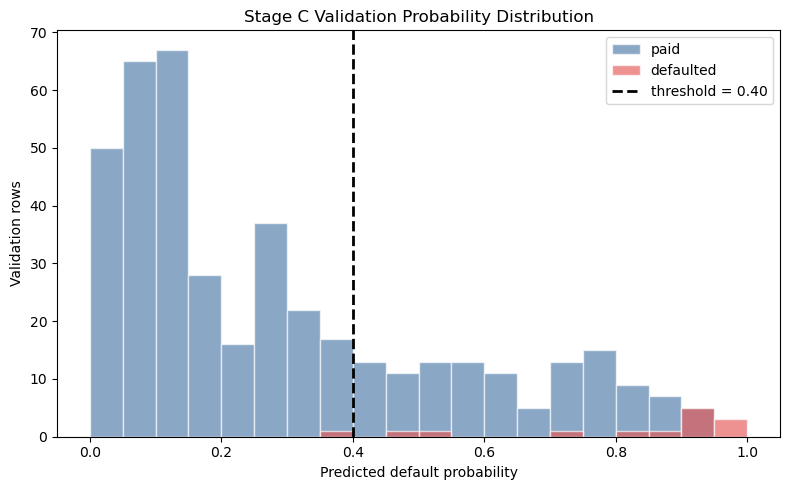

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(0, 1, 21)
for defaulted_value, label, color in [(0, 'paid', '#4C78A8'), (1, 'defaulted', '#E45756')]:
    subset = validation_eval.loc[validation_eval['defaulted'].eq(defaulted_value), 'stage_c_default_probability']
    ax.hist(subset, bins=bins, alpha=0.65, label=label, color=color, edgecolor='white')

threshold = stage_c_metrics.loc[stage_c_metrics['split'].eq('validation'), 'threshold'].iloc[0]
ax.axvline(threshold, color='black', linestyle='--', linewidth=2, label=f'threshold = {threshold:.2f}')
ax.set_title('Stage C Validation Probability Distribution')
ax.set_xlabel('Predicted default probability')
ax.set_ylabel('Validation rows')
ax.legend()
plt.tight_layout()

In [27]:
diagnostic_cols = [
    'transaction_id', 'invoice_date', 'status', 'defaulted',
    'stage_c_default_probability', 'stage_c_predicted_default',
    'stage_b_benchmark_score', 'stage_b_benchmark_band',
    'stage_b_peer_outlier_count', 'stage_b_peer_outlier_reasons',
]

stage_c_false_negatives = (
    validation_eval.loc[validation_eval['stage_c_error_type'].eq('false_negative'), diagnostic_cols]
    .sort_values('stage_c_default_probability')
)
stage_c_false_positives = (
    validation_eval.loc[validation_eval['stage_c_error_type'].eq('false_positive'), diagnostic_cols]
    .sort_values('stage_c_default_probability', ascending=False)
    .head(15)
)

display(Markdown('**False negatives: actual defaults missed at the selected threshold**'))
display(stage_c_false_negatives)
display(Markdown('**Highest-probability false positives: paid deals flagged for review**'))
display(stage_c_false_positives)

**False negatives: actual defaults missed at the selected threshold**

,transaction_id,invoice_date,status,defaulted,stage_c_default_probability,stage_c_predicted_default,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_outlier_count,stage_b_peer_outlier_reasons
161,TX-003019,2025-11-07,defaulted,1,0.3503,0,50.0500,Medium,7,outstanding_to_revenue_est high vs goods_categ...


**Highest-probability false positives: paid deals flagged for review**

,transaction_id,invoice_date,status,defaulted,stage_c_default_probability,stage_c_predicted_default,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_outlier_count,stage_b_peer_outlier_reasons
47,TX-004129,2025-10-09,paid,0,0.9149,1,69.1351,Medium,6,exp_debt_to_equity high vs goods_category=Meta...
398,TX-002988,2026-01-27,paid,0,0.9149,1,65.0546,Medium,7,outstanding_to_revenue_est high vs goods_categ...
11,TX-000600,2025-10-03,paid,0,0.9137,1,68.4518,Medium,10,outstanding_to_revenue_est high vs goods_categ...
319,TX-003003,2025-12-19,paid,0,0.9027,1,56.3422,Medium,1,buyer_dso_gap_days high vs goods_category=Metals
165,TX-000617,2025-11-08,paid,0,0.9026,1,70.5854,High,7,outstanding_to_revenue_est high vs goods_categ...
340,TX-000723,2025-12-29,paid,0,0.8987,1,68.6195,Medium,9,outstanding_to_revenue_est high vs goods_categ...
410,TX-002396,2026-02-05,paid,0,0.8983,1,65.0149,Medium,6,outstanding_to_revenue_est high vs goods_categ...
388,TX-001642,2026-01-20,paid,0,0.8809,1,65.8487,Medium,8,outstanding_to_revenue_est high vs goods_categ...
363,TX-003183,2026-01-07,paid,0,0.8799,1,70.2554,High,7,outstanding_to_revenue_est high vs goods_categ...
199,TX-001328,2025-11-14,paid,0,0.8759,1,67.6155,Medium,7,outstanding_to_revenue_est high vs goods_categ...


In [28]:
prediction_cols = [
    'transaction_id', 'invoice_date', 'status', 'defaulted',
    'stage_c_default_probability', 'stage_c_predicted_default',
    'stage_b_benchmark_score', 'stage_b_benchmark_band',
    'stage_b_peer_outlier_count', 'stage_b_peer_outlier_reasons'
]

stage_c_validation_predictions.sort_values(
    'stage_c_default_probability', ascending=False
)[prediction_cols].head(20)

,transaction_id,invoice_date,status,defaulted,stage_c_default_probability,stage_c_predicted_default,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_outlier_count,stage_b_peer_outlier_reasons
127,TX-001804,2025-10-28,defaulted,1,0.9758,1,75.0417,High,14,outstanding_to_revenue_est high vs goods_categ...
14,TX-004618,2025-10-04,defaulted,1,0.9677,1,70.9904,High,7,outstanding_to_revenue_est high vs goods_categ...
120,TX-000034,2025-10-26,defaulted,1,0.9534,1,70.2411,High,9,outstanding_to_revenue_est high vs goods_categ...
0,TX-004630,2025-10-01,defaulted,1,0.9490,1,67.1231,Medium,9,outstanding_to_revenue_est high vs goods_categ...
22,TX-000764,2025-10-05,defaulted,1,0.9440,1,69.5171,Medium,8,outstanding_to_revenue_est high vs goods_categ...
48,TX-002237,2025-10-09,defaulted,1,0.9410,1,68.9848,Medium,10,outstanding_to_revenue_est high vs goods_categ...
50,TX-002879,2025-10-10,defaulted,1,0.9308,1,67.2252,Medium,10,outstanding_to_revenue_est high vs goods_categ...
47,TX-004129,2025-10-09,paid,0,0.9149,1,69.1351,Medium,6,exp_debt_to_equity high vs goods_category=Meta...
398,TX-002988,2026-01-27,paid,0,0.9149,1,65.0546,Medium,7,outstanding_to_revenue_est high vs goods_categ...
11,TX-000600,2025-10-03,paid,0,0.9137,1,68.4518,Medium,10,outstanding_to_revenue_est high vs goods_categ...


In [29]:
layer1_validation_predictions.sort_values(
    ['layer1_flagged_for_review', 'stage_c_default_probability'],
    ascending=[False, False],
).head(20)

,transaction_id,invoice_date,status,defaulted,stage_a_decision,stage_a_reject_reasons,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_outlier_count,stage_c_default_probability,stage_c_predicted_default,layer1_flagged_for_review,layer1_route
72,TX-001804,2025-10-28,defaulted,1,PASS_STAGE_A,NaN,75.0417,High,14.0000,0.9758,1,1,Stage C high-risk review
11,TX-004618,2025-10-04,defaulted,1,PASS_STAGE_A,NaN,70.9904,High,7.0000,0.9677,1,1,Stage C high-risk review
66,TX-000034,2025-10-26,defaulted,1,PASS_STAGE_A,NaN,70.2411,High,9.0000,0.9534,1,1,Stage C high-risk review
4,TX-004630,2025-10-01,defaulted,1,PASS_STAGE_A,NaN,67.1231,Medium,9.0000,0.9490,1,1,Stage C high-risk review
14,TX-000764,2025-10-05,defaulted,1,PASS_STAGE_A,NaN,69.5171,Medium,8.0000,0.9440,1,1,Stage C high-risk review
32,TX-002237,2025-10-09,defaulted,1,PASS_STAGE_A,NaN,68.9848,Medium,10.0000,0.9410,1,1,Stage C high-risk review
38,TX-002879,2025-10-10,defaulted,1,PASS_STAGE_A,NaN,67.2252,Medium,10.0000,0.9308,1,1,Stage C high-risk review
34,TX-004129,2025-10-09,paid,0,PASS_STAGE_A,NaN,69.1351,Medium,6.0000,0.9149,1,1,Stage C high-risk review
249,TX-002988,2026-01-27,paid,0,PASS_STAGE_A,NaN,65.0546,Medium,7.0000,0.9149,1,1,Stage C high-risk review
6,TX-000600,2025-10-03,paid,0,PASS_STAGE_A,NaN,68.4518,Medium,10.0000,0.9137,1,1,Stage C high-risk review


In [30]:
open_prediction_cols = [
    'transaction_id', 'invoice_date', 'status',
    'stage_c_default_probability',
    'stage_b_benchmark_score', 'stage_b_benchmark_band',
    'stage_b_peer_outlier_count', 'stage_b_peer_outlier_reasons'
]

stage_c_open_predictions.sort_values(
    'stage_c_default_probability', ascending=False
)[open_prediction_cols].head(20)

,transaction_id,invoice_date,status,stage_c_default_probability,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_outlier_count,stage_b_peer_outlier_reasons
0,TX-000507,2025-12-21,open,0.9784,74.9697,High,8,outstanding_to_revenue_est high vs goods_categ...
1,TX-000417,2026-01-26,open,0.9730,72.6262,High,14,ticket_to_revenue_est high vs goods_category=P...
2,TX-003216,2025-12-03,open,0.9639,71.2119,High,7,outstanding_to_revenue_est high vs goods_categ...
3,TX-002051,2025-12-05,open,0.9636,68.2455,Medium,9,outstanding_to_revenue_est high vs goods_categ...
4,TX-001275,2026-02-08,open,0.9630,70.6203,High,7,outstanding_to_revenue_est high vs goods_categ...
5,TX-000794,2026-03-28,open,0.9617,71.6466,High,9,outstanding_to_revenue_est high vs goods_categ...
6,TX-004364,2026-02-25,open,0.9612,71.3719,High,10,outstanding_to_revenue_est high vs goods_categ...
7,TX-004123,2026-02-16,open,0.9611,73.3455,High,10,outstanding_to_revenue_est high vs goods_categ...
8,TX-000942,2025-08-21,open,0.9605,71.5063,High,8,outstanding_to_revenue_est high vs goods_categ...
9,TX-002589,2026-01-06,open,0.9579,73.0544,High,10,outstanding_to_revenue_est high vs goods_categ...


## 6. Stage C Plots

### stage_c_precision_recall.png

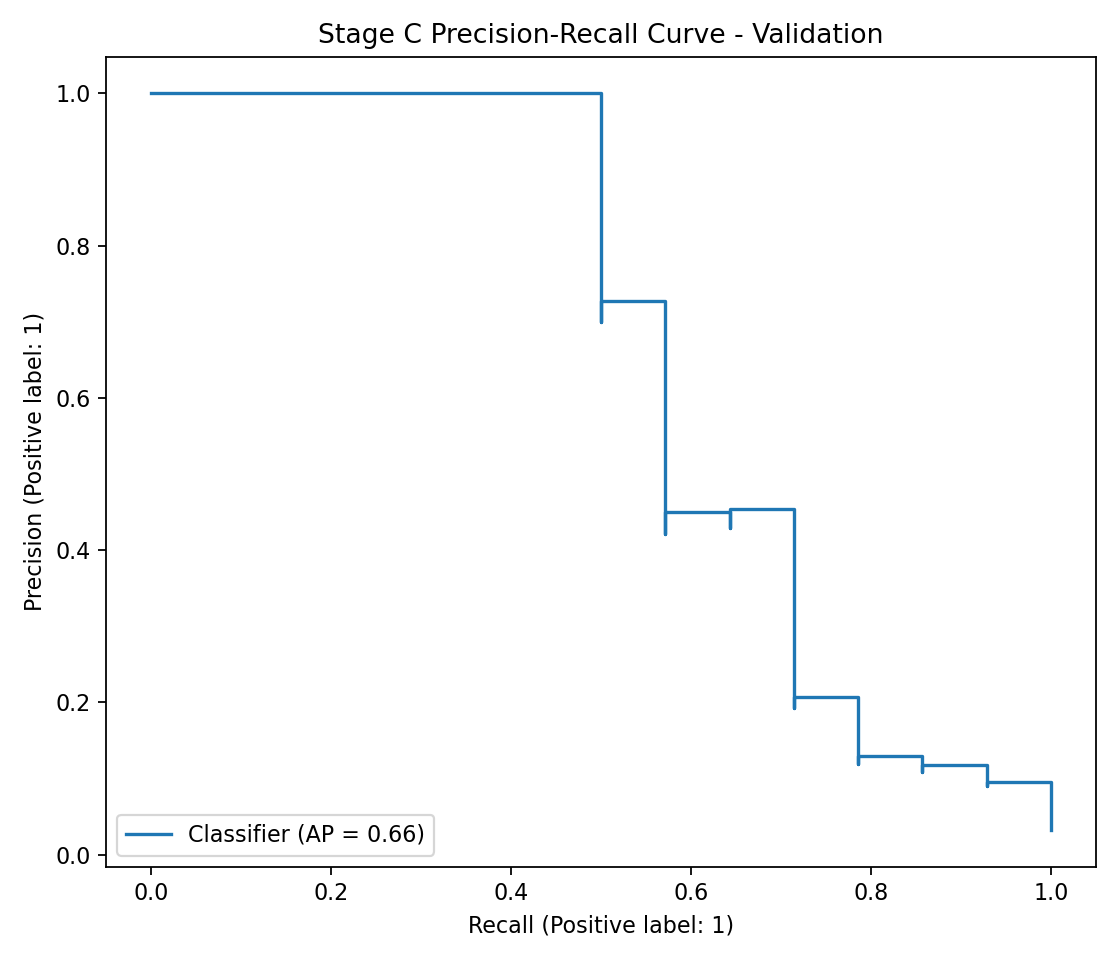

### stage_c_calibration.png

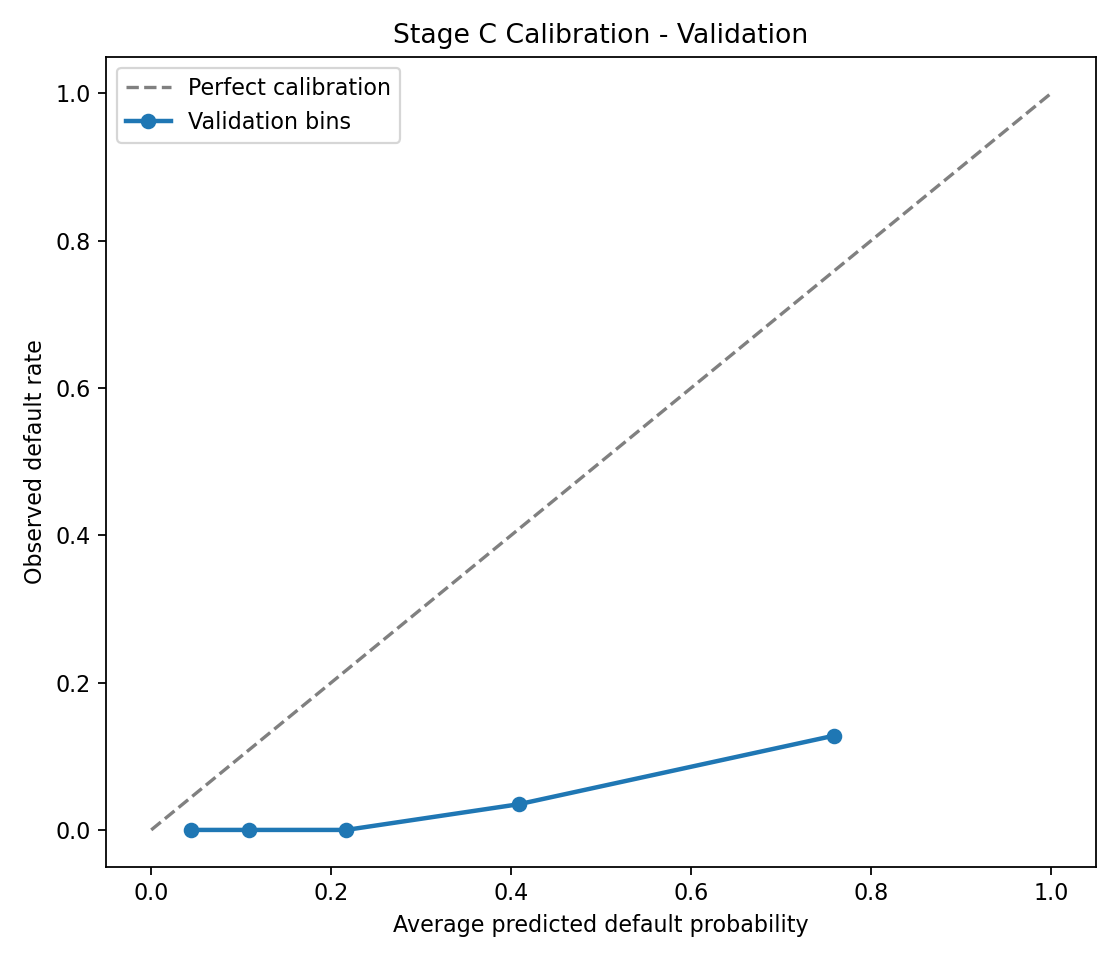

### stage_c_confusion_matrix.png

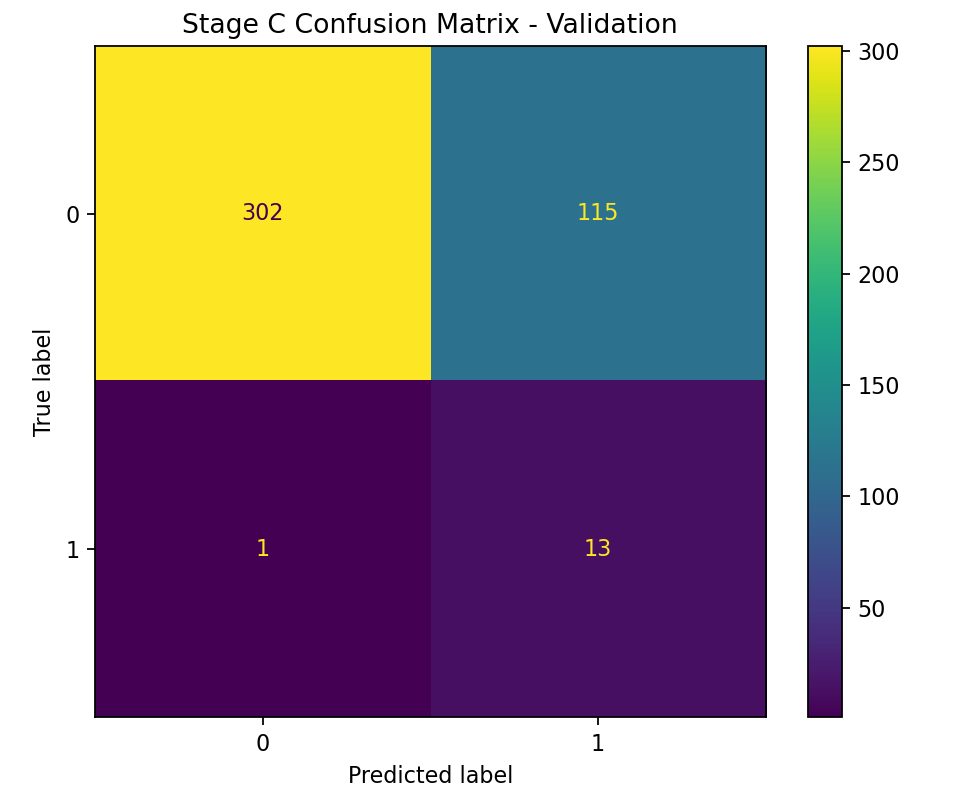

### stage_c_feature_importance.png

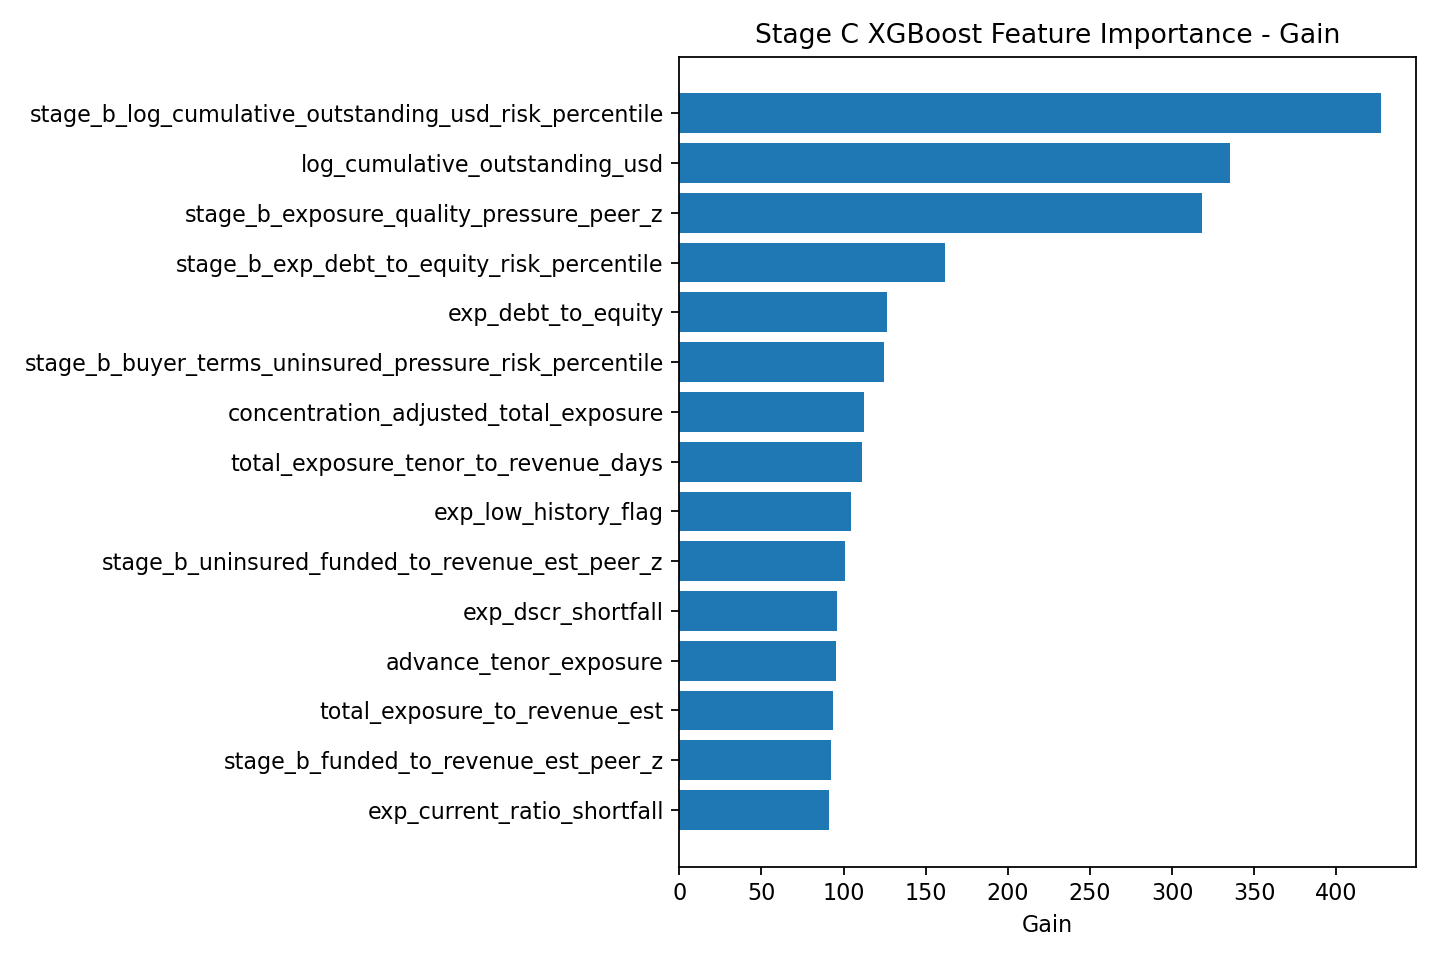

In [31]:
for image_name in [
    'stage_c_precision_recall.png',
    'stage_c_calibration.png',
    'stage_c_confusion_matrix.png',
    'stage_c_feature_importance.png',
]:
    display(Markdown(f'### {image_name}'))
    display(Image(filename=str(REPORTS_DIR / image_name)))

## 7. Layer 1 Summary

This notebook now maps directly to section 3.1:

| Requirement | Where shown |
| --- | --- |
| Stage A configurable hard filters | `config/hard_filters.json`, Stage A rule table, Stage A decision output |
| Stage B cross-sector features | Stage B feature config and feature summary |
| Within-sector outlier detection | Stage B peer outlier table and reason strings |
| New/sparse sector handling | `stage_b_peer_group_source`, fallback logic documented in Stage B notes |
| Stage C probability classifier | XGBoost model outputs and validation predictions |
| Class imbalance | `scale_pos_weight` in Stage C report |
| Out-of-time validation | train/validation split outputs and Stage C validation metrics |
| AUC-PR / KS | `stage_c_metrics` |
| Calibration plot/table | Stage C calibration table and plot |
| Explainability | XGBoost feature importance plus Stage B human-readable benchmark/outlier drivers |
| Confusion matrix and threshold | Stage C confusion matrix plot and metrics table |
| End-to-end Layer 1 default capture | `layer1_validation_metrics` and `layer1_validation_predictions` |

Key caveat: Stage C is a review-queue model. It is now much better at ranking defaults, but its probabilities should still be treated as risk scores rather than pricing-grade calibrated default probabilities.